# SORDINO electrical stimulation fMRI: post-stimulation analysis (LTP)

Continues on the output of `mol_fMRI_sordino_preprocessing.ipynb` and looks at the slow signal change after the stimulation. Pick the analysis folder of a finished preprocessing run (the folder with `session.json`). The volume TR is taken from the stitched series (2.4 s for the sordino scans, not the 1 s that the converted NIfTI files claim), so all windows and bins below are given in seconds and converted to volumes.

1. Load the session and the motion-corrected stitched series.
2. Set a baseline window and a signal window on the stitched series (as in `mol_fMRI_v5.4.ipynb`). By default the baseline is 50 volumes after the start of the last (post-stimulation) scan and the signal window is at about 3/4 of it, so the signal ramp-up has time to develop but the window does not run into the end of the scan.
3. Register to the atlas and compare signal and baseline in every atlas region.
4. Compute voxelwise signal change maps and t-maps and move them to atlas space for group analysis.

In [1]:
import electric_stim_helpers, electric_stim_session, electric_stim_atlas, sordino_helpers
from sordino_helpers import *
from electric_stim_helpers import *
from electric_stim_session import *
from electric_stim_atlas import *
from fmri_paths import get_fmri_root

# Data root: environment variable FMRI_ROOT, fmri_root.txt or the folder containing this repository (see fmri_paths.py)
FMRI_ROOT = get_fmri_root()

selected_session = FileChooser(f"{FMRI_ROOT}/AnalysedData", layout=widgets.Layout(width="1080px"))
selected_session.show_only_dirs = True
display(selected_session)

FileChooser(path='/Volumes/pschmidt/fmri_analysis/AnalysedData', filename='', title='', show_hidden=False, sel…

In [4]:
session, session_source = load_session(selected_session.selected_path)

in_path = session["in_path"]
subject_id = session["subject_id"]
func_scan_numbers = session["func_scan_numbers"]
analysed_func_dir = session["analysed_func_dir"]
analysis_dir = session["analysis_dir"]
mask_file = session["mask_file"]
structural_file_for_coregistration = session["structural_file_for_coregistration"]
scan_ranges = read_scan_ranges(analysed_func_dir)

os.chdir(analysis_dir)
require_files([analysed_func_dir / "mc_func.nii.gz", analysis_dir / "mean_mc_func.nii.gz", mask_file, structural_file_for_coregistration,
               analysed_func_dir / "scan_boundaries.csv"],
              "Run the preprocessing notebook up to the structural processing first.")

print_statement(f"Session {session_source}", bcolors.NOTIFICATION)
print_statement(f"Subject {subject_id}, functional scans {', '.join(func_scan_numbers)} (stitched)", bcolors.NOTIFICATION)
print_statement(f"Analysis folder: {analysis_dir}", bcolors.NOTIFICATION)
for scan, start, end in scan_ranges:
    print(f"  Scan {scan}: volumes {start}-{end}")

# Volume TR: written to the stitched series by the preprocessing (session.json); older sessions read it from the method files
if session.get("tr"):
    tr = float(session["tr"])
else:
    tr = float(sordino_param_extract(Path(in_path) / func_scan_numbers[-1])["VolTR"])

func_4d = nib.load(str(analysed_func_dir / "mc_func.nii.gz")).get_fdata(dtype=np.float32)
brain = nib.load(mask_file).get_fdata() > 0
if brain.shape != func_4d.shape[:3]:
    raise ValueError(f"Brain mask {brain.shape} and functional data {func_4d.shape[:3]} are on different grids.")
n_total = func_4d.shape[-1]
brain_ts = func_4d[brain].mean(axis=0)
print_statement(f"{n_total} volumes, TR {tr} s, {int(brain.sum())} voxels in the brain mask", bcolors.NOTIFICATION)

Session /Volumes/pschmidt/fmri_analysis/AnalysedData/Sordino_converted/RGRO_261026_0224_RN_SD_468/stitched_71_sordino_norm/analysis/session.json
Subject RGRO_261026_0224_RN_SD_468, functional scans 71 (stitched)
Analysis folder: /Volumes/pschmidt/fmri_analysis/AnalysedData/Sordino_converted/RGRO_261026_0224_RN_SD_468/stitched_71_sordino_norm/analysis
  Scan 1: volumes 0-239
240 volumes, TR 4.990442 s, 8726 voxels in the brain mask


# Baseline and Signal Window

Volume indices (0-based) refer to the stitched series, see the scan ranges printed above. Both windows have the same length (default 300 s). The defaults follow the last scan: baseline 50 s after its start, signal window starting at 3/4 of it. The sordino scans have no start-up transient (10 s of dummy scans before every scan), so the offset can be shortened. Check the whole-brain time course below before trusting the windows: a sudden step in the signal (e.g. 466 scan 36 around volume 325 of the scan) is not a stimulation effect and must stay out of both windows.

Percent signal change is relative to the mean of the baseline window. To compare the two windows, each window is cut into non-overlapping bins (`BIN_S` seconds); a Welch t-test then compares the signal bins with the baseline bins. Testing bin means instead of single volumes keeps the strong temporal autocorrelation of the fMRI signal from inflating the statistics.

In [5]:
BASELINE_OFFSET_S = 50  # seconds after the start of the last scan; the signal is still settling right after a scan start
WINDOW_S = 300  # default length of the baseline and the signal window
post_scan, post_start, post_end = scan_ranges[-1]
n_post = post_end - post_start + 1

input_layout = widgets.Layout(width="280px", flex="0 0 auto")
label_style = {'description_width': '180px'}
base_start_idx = widgets.IntText(value=post_start + int(round(BASELINE_OFFSET_S / tr)), description="Baseline Start Index:", layout=input_layout, style=label_style)
sig_start_idx = widgets.IntText(value=post_start + int(0.75 * n_post), description="Signal Start Index:", layout=input_layout, style=label_style)
win_idx = widgets.IntText(value=int(round(WINDOW_S / tr)), description="Window Duration (in vols):", layout=input_layout, style=label_style)
display(widgets.HBox([base_start_idx, sig_start_idx, win_idx],
    layout=widgets.Layout(width="100%", justify_content="space-between", align_items="center", padding="12px", border="3px solid #444", border_radius="10px", background_color="#1e1e1e")))

Baseline window: volumes 5-49; signal window: volumes 160-204; 7 bins of 6 volumes (30 s) each


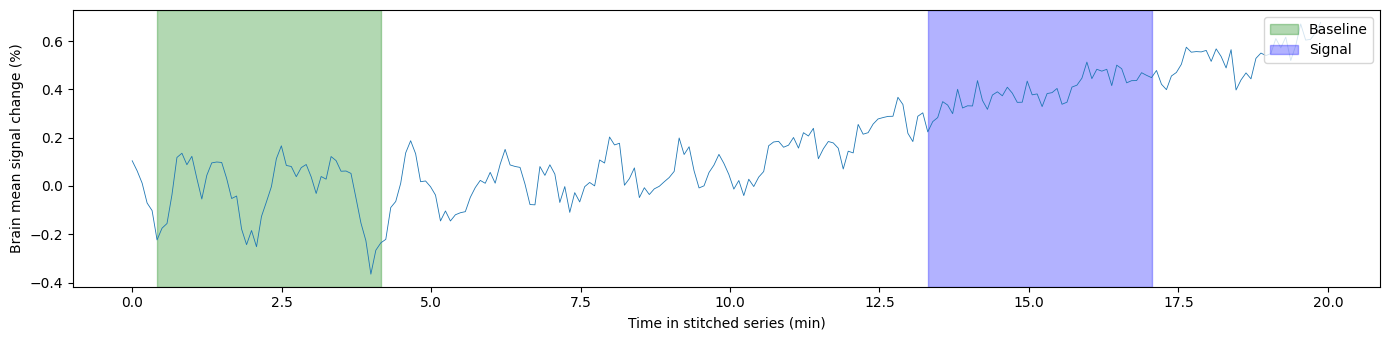

In [6]:
BIN_S = 30  # length of the bins that are tested against each other

base_start, sig_start, win = int(base_start_idx.value), int(sig_start_idx.value), int(win_idx.value)
base_end, sig_end = base_start + win, sig_start + win
if min(base_start, sig_start) < 0 or max(base_end, sig_end) > n_total:
    raise ValueError(f"Windows must lie within the stitched series (0-{n_total - 1}).")
if base_start < sig_end and sig_start < base_end:
    raise ValueError("Baseline and signal window overlap.")

bin_vols = max(1, int(round(BIN_S / tr)))
n_bins = win // bin_vols
if n_bins < 3:
    raise ValueError(f"Window of {win} volumes holds only {n_bins} bins of {BIN_S} s; increase the window or decrease BIN_S.")


def window_bins(x, start):
    """Mean of every non-overlapping bin of the window starting at `start` (last axis is time)."""
    seg = x[..., start:start + n_bins * bin_vols]
    return seg.reshape(*seg.shape[:-1], n_bins, bin_vols).mean(axis=-1)


def scan_boundaries():
    return [start for _, start, _ in scan_ranges[1:]]


def mark_windows(ax, to_time=lambda v: v * tr / 60):
    ax.axvspan(to_time(base_start), to_time(base_end), color="green", alpha=0.3, label="Baseline")
    ax.axvspan(to_time(sig_start), to_time(sig_end), color="blue", alpha=0.3, label="Signal")
    for b in scan_boundaries():
        ax.axvline(to_time(b), color="k", ls="--", lw=0.8)


print_statement(f"Baseline window: volumes {base_start}-{base_end - 1}; signal window: volumes {sig_start}-{sig_end - 1}; "
                f"{n_bins} bins of {bin_vols} volumes ({bin_vols * tr:.0f} s) each", bcolors.OKGREEN)

# Whole-brain mean as a check of the window choice (dashed lines = scan boundaries)
brain_base = window_bins(brain_ts, base_start).mean()
fig, ax = plt.subplots(figsize=(14, 3.5))
ax.plot(np.arange(n_total) * tr / 60, (brain_ts - brain_base) / brain_base * 100, lw=0.6)
mark_windows(ax)
ax.set_xlabel("Time in stitched series (min)")
ax.set_ylabel("Brain mean signal change (%)")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

# Atlas Coregistration and Signal Change per Brain Region

Select the species in the widget cell below; it fills in the matching atlas:
- **Rat:** SIGMA in vivo template, rigid registration.
- **Mouse:** DSURQE (MICe) template. It is an ex vivo, whole-head average, so it is brain-masked, downsampled to 0.1 mm for registration, and registered with a scaling term and `nmi` cost. Any other mouse template/label pair (e.g. Allen CCFv3) can be entered instead.

The registration is the same as in `mol_fMRI_electric_stim_analysis.ipynb` (structural scan to the mean functional image, then to the atlas) and is stored in the `roi_atlas_<species>/` folder of this analysis, so a registration that already exists is reused. Check the quality control images: the sordino mean image has a zero-echo-time contrast and a lower resolution (0.6 mm) than the EPI, so the registration settings are not tested for it. The multi-label atlas is resampled once onto the functional grid with nearest-neighbour interpolation, so the functional data itself is never interpolated.

Then the mean time course of every atlas region (inside the brain mask) is extracted, and the signal window is compared with the baseline window (Welch t-test on the bins), with Benjamini-Hochberg FDR correction across regions. This replaces manually drawn ROIs. Outputs go to `roi_atlas_<species>/poststim/`:
- `poststim_roi_response.csv`: every region with baseline-normalised signal change, t, p and FDR-corrected q; `poststim_roi_responders.csv` lists only the regions with a significant increase.
- `poststim_roi_psc_timeseries_all.csv`: percent signal change time course of every region.
- `poststim_roi_response_map.nii.gz`: signal change of the responding regions on the functional grid.
- `poststim_roi_response_top_increases.svg` / `..._top_decreases.svg`: time courses of the `N_TOP` regions with the strongest signal increase and the strongest decrease (ranked by t, or by the size of the signal change with `RANK_BY`); the same regions are printed as tables.
- `plots/`: one figure per region (time course with both windows and the bin values); the responders are also in `plots/responders/`.

Optional label names CSV: either columns `id,name`, or the DSURQE / SIGMA structure lists with separate left and right label columns (regions then get an `_L` / `_R` suffix). Without it, regions are named `label_<id>`.

In [7]:
SPECIES_ATLAS = species_atlas_config(FMRI_ROOT)

atlas_layout = widgets.Layout(width="700px")
atlas_style = {"description_width": "160px"}
species_dropdown = widgets.Dropdown(options=list(SPECIES_ATLAS), value="rat", description="Species:", layout=widgets.Layout(width="280px"), style=atlas_style)
atlas_template_entered = widgets.Text(description="Atlas template:", layout=atlas_layout, style=atlas_style)
atlas_labels_entered = widgets.Text(description="Atlas labels:", layout=atlas_layout, style=atlas_style)
atlas_mask_entered = widgets.Text(placeholder="optional, restricts the template to the brain", description="Template brain mask:", layout=atlas_layout, style=atlas_style)
atlas_names_entered = widgets.Text(placeholder="optional CSV (id,name or left/right label columns)", description="Label names CSV:", layout=atlas_layout, style=atlas_style)


def fill_atlas_defaults(change=None):
    cfg = SPECIES_ATLAS[species_dropdown.value]
    atlas_template_entered.value = cfg["template"]
    atlas_labels_entered.value = cfg["labels"]
    atlas_mask_entered.value = cfg["mask"]
    atlas_names_entered.value = cfg["names"]


species_dropdown.observe(fill_atlas_defaults, names="value")
fill_atlas_defaults()

display(widgets.VBox([species_dropdown, atlas_template_entered, atlas_labels_entered, atlas_mask_entered, atlas_names_entered],
    layout=widgets.Layout(padding="12px", border="3px solid #444", border_radius="10px", background_color="#1e1e1e")))


**************************************************************************************************************************************
                                      Registering structural to functional and to the rat atlas                                       
**************************************************************************************************************************************

struct2func_masked registration already exists. Skipping.
struct2atlas registration already exists. Skipping.
[COMMAND] cat_matvec -ONELINE /Volumes/pschmidt/fmri_analysis/AnalysedData/Sordino_converted/RGRO_261026_0224_RN_SD_468/stitched_71_sordino_norm/analysis/roi_atlas_rat/struct2func.matvec /Volumes/pschmidt/fmri_analysis/AnalysedData/Sordino_converted/RGRO_261026_0224_RN_SD_468/stitched_71_sordino_norm/analysis/roi_atlas_rat/struct2atlas.matvec -I
[COMMAND] 3dAllineate -source /Volumes/pschmidt/fmri_analysis/atlas/SIGMA_rat_atlas/sigma_wistar_rat_brain_templatesandatlases_version1

++ 3dAllineate: AFNI version=AFNI_26.2.06 (Sep  3 2026) [64-bit]
++ Authored by: Zhark the Registrator
++ Source dataset: /Volumes/pschmidt/fmri_analysis/atlas/SIGMA_rat_atlas/sigma_wistar_rat_brain_templatesandatlases_version1-2-1_2022-08-26/SIGMA_Wistar_Rat_Brain_TemplatesAndAtlases_Version1.2.1/SIGMA_Rat_Brain_Atlases/SIGMA_Anatomical_Atlas/InVivo_Atlas/SIGMA_InVivo_Anatomical_Brain_Atlas.nii
++ Base dataset:   (not given)
++ Loading datasets into memory
 +        -cmass x y z shifts =    0.000    0.000    0.000
 +  shift search range is +/- =    6.115   10.449    6.115
++ OpenMP thread count = 11
++ ========== Applying transformation to 1 sub-bricks ==========
++ Output dataset /Volumes/pschmidt/fmri_analysis/AnalysedData/Sordino_converted/RGRO_261026_0224_RN_SD_468/stitched_71_sordino_norm/analysis/roi_atlas_rat/atlas_labels_funcspace.nii.gz
++ 3dAllineate: total CPU time = 0.1 sec  Elapsed = 0.2
++ ###########################################################


[OK] Atlas labels in functional space: /Volumes/pschmidt/fmri_analysis/AnalysedData/Sordino_converted/RGRO_261026_0224_RN_SD_468/stitched_71_sordino_norm/analysis/roi_atlas_rat/atlas_labels_funcspace.nii.gz


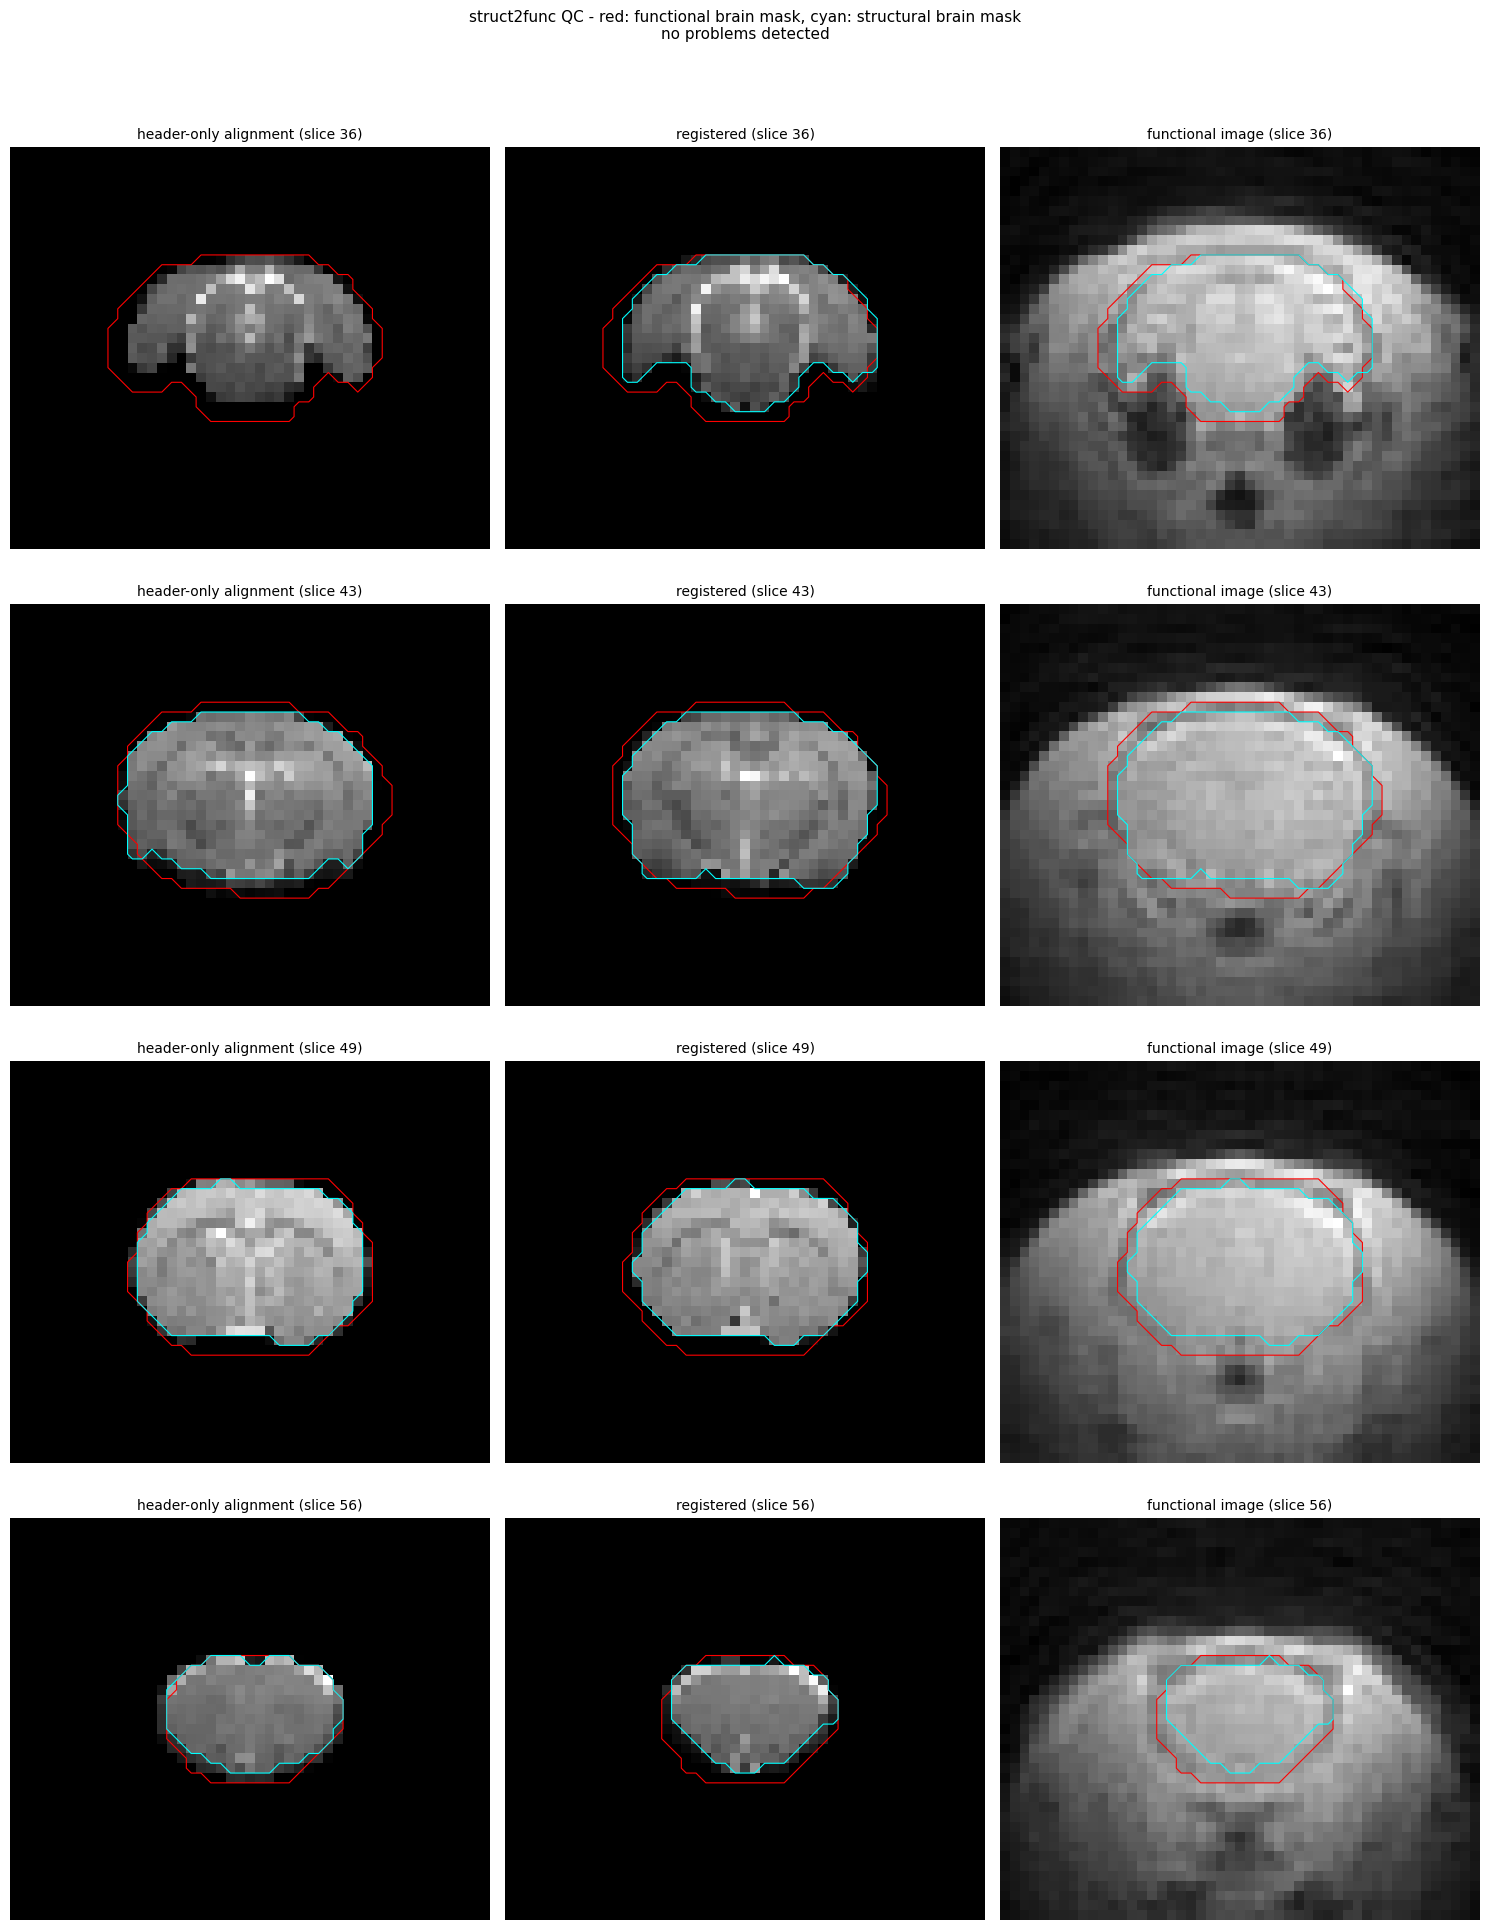

--- struct2func QC ---
Estimated transform (limits: 2 mm, 5 deg):
  x-shift (mm)      0.247
  y-shift (mm)     -0.810
  z-shift (mm)     -0.095
  z-angle (deg)     1.447
  x-angle (deg)     1.735
  y-angle (deg)    -1.111

NMI with the functional image (higher is better): registered 1.0667, header-only 1.0520
Brain mask Dice (in structural coverage): registered 0.871, header-only 0.845
Mean in-plane edge distance (mm):         registered 0.630, header-only 0.540
Overlay image: /Volumes/pschmidt/fmri_analysis/AnalysedData/Sordino_converted/RGRO_261026_0224_RN_SD_468/stitched_71_sordino_norm/analysis/roi_atlas_rat/qc/qc_struct2func.png

RESULT: no problems detected
[OK] struct2func QC: no problems detected


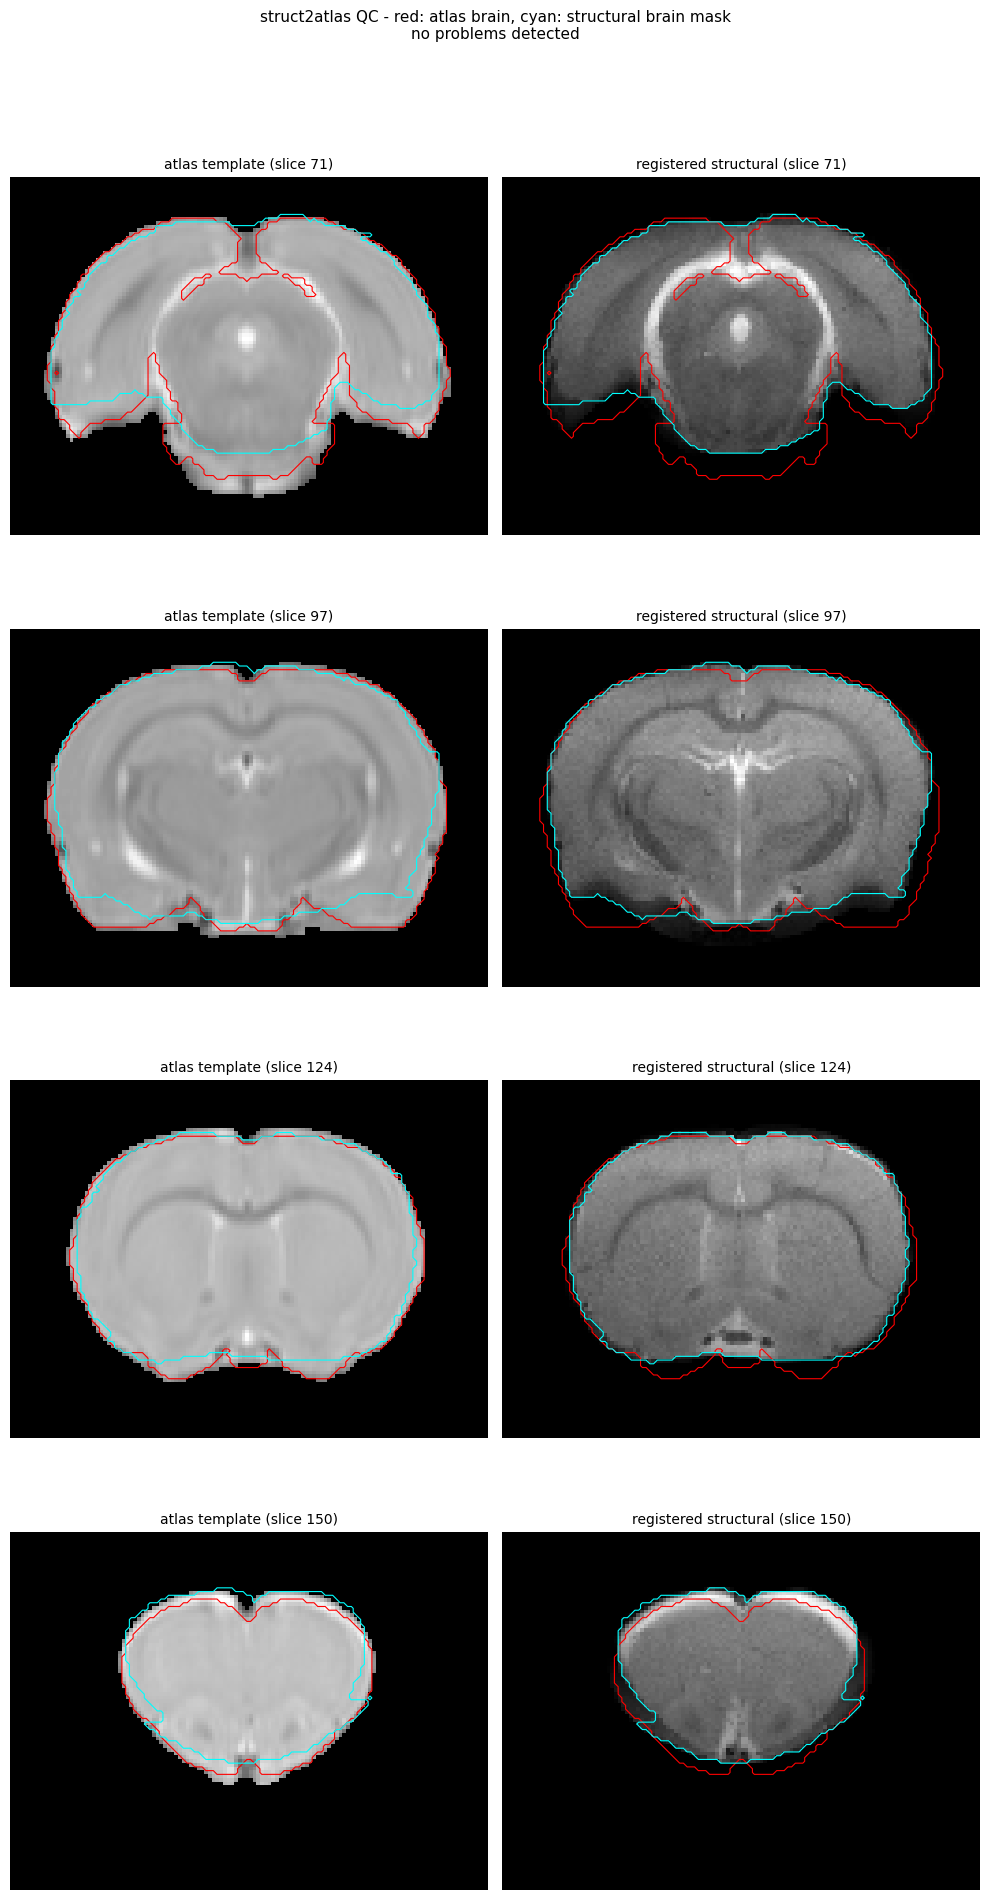

--- struct2atlas QC ---
Estimated transform:
  x-shift (mm)     -0.551
  y-shift (mm)     -2.763
  z-shift (mm)     -2.636
  z-angle (deg)     0.817
  x-angle (deg)    -7.433
  y-angle (deg)     1.752

Brain mask Dice (in structural coverage): 0.779
Distance between the centres of the structural and atlas brain: 2.50 mm
Brain volume structural / atlas (in structural coverage): 0.68
Overlay image: /Volumes/pschmidt/fmri_analysis/AnalysedData/Sordino_converted/RGRO_261026_0224_RN_SD_468/stitched_71_sordino_norm/analysis/roi_atlas_rat/qc/qc_struct2atlas.png

RESULT: no problems detected
[OK] struct2atlas QC: no problems detected


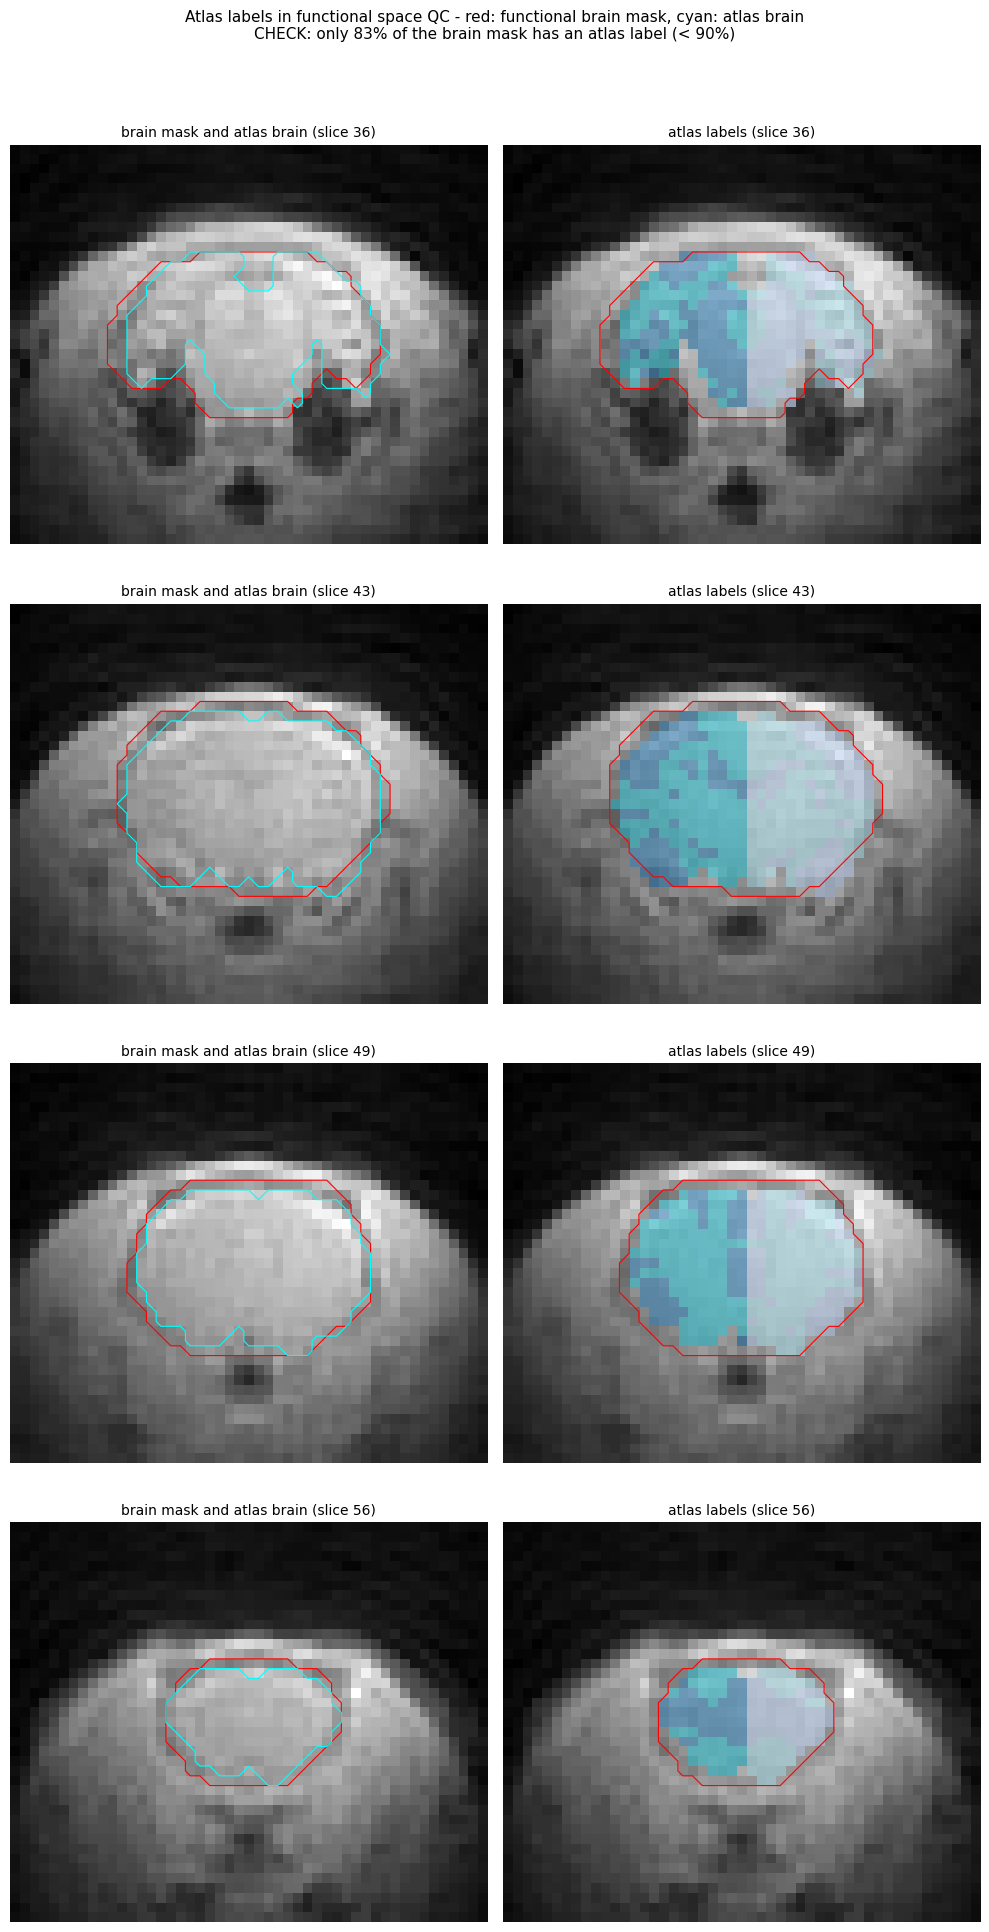

--- Atlas labels QC ---
Share of the brain mask voxels that have an atlas label: 83.3%
Dice between atlas brain (labels > 0) and functional brain mask: 0.755
Regions inside the brain mask: 202, of which 41 have fewer than 5 voxels
Overlay image: /Volumes/pschmidt/fmri_analysis/AnalysedData/Sordino_converted/RGRO_261026_0224_RN_SD_468/stitched_71_sordino_norm/analysis/roi_atlas_rat/qc/qc_labels_funcspace.png

RESULT: CHECK: only 83% of the brain mask has an atlas label (< 90%)
[WARNING] only 83% of the brain mask has an atlas label (< 90%)


In [8]:
OPEN_FSLEYES = True  # look at the registration / the maps in fsleyes

species = species_dropdown.value
species_cfg = SPECIES_ATLAS[species]
atlas_template = Path(atlas_template_entered.value.strip()).resolve()
atlas_labels = Path(atlas_labels_entered.value.strip()).resolve()
atlas_mask_text = atlas_mask_entered.value.strip()
for f in (atlas_template, atlas_labels) + ((Path(atlas_mask_text),) if atlas_mask_text else ()):
    if not f.is_file():
        raise FileNotFoundError(f"{f} (atlas files for {species} not found; check the paths above)")

atlas_dir = analysis_dir / f"roi_atlas_{species}"
atlas_dir.mkdir(exist_ok=True)
post_dir = atlas_dir / "poststim"
post_dir.mkdir(exist_ok=True)
func_reference = analysis_dir / "mean_mc_func.nii.gz"

print_header(f"Registering structural to functional and to the {species} atlas", bcolors.HEADER)
composite, labels_funcspace = register_to_atlas(Path(structural_file_for_coregistration), func_reference, mask_file, atlas_dir, species_cfg,
                                                atlas_template, atlas_labels, atlas_mask_text)

# Quality control of the registrations (overlay images and reports in the qc folder, warnings are printed)
registration_qc(structural_file_for_coregistration, func_reference, mask_file, atlas_dir, species_cfg, atlas_template, atlas_labels,
                labels_funcspace, struct_mask=structural_mask_file(Path(structural_file_for_coregistration).parent), atlas_mask=atlas_mask_text)
 
# Check the registration visually before trusting the regions
if OPEN_FSLEYES:
    subprocess.run(["fsleyes", str(func_reference), str(labels_funcspace), "-cm", "random", "-a", "40"])

161 regions analysed, 135 with a significant signal increase (FDR q < 0.05)
 label_id                                       name  n_voxels    baseline  signal_psc         t            p        q_fdr  responder
      652          Retosplenial Dysgranular Cortex_R        92 116224128.0    0.606222 19.213250 4.440097e-10 3.746691e-08       True
      141                        Entorhinal Cortex_L       158  84875624.0    0.550349 18.164806 4.654275e-10 3.746691e-08       True
      511                     Primary Motor Cortex_L       109 108695000.0    0.724861 16.463556 1.542540e-09 8.278300e-08       True
       92                          Cornu Ammonis 3_R        70 111079112.0    0.487199 14.677311 5.025085e-09 2.022597e-07       True
      622     Primary Visual Cortex Binocular Area_R        47 121457272.0    0.486914 14.855061 6.483453e-09 2.087672e-07       True
      312       Medial Parietal Associative Cortex_R         8 122118480.0    1.333570 18.572938 1.605699e-08 4.308625e-

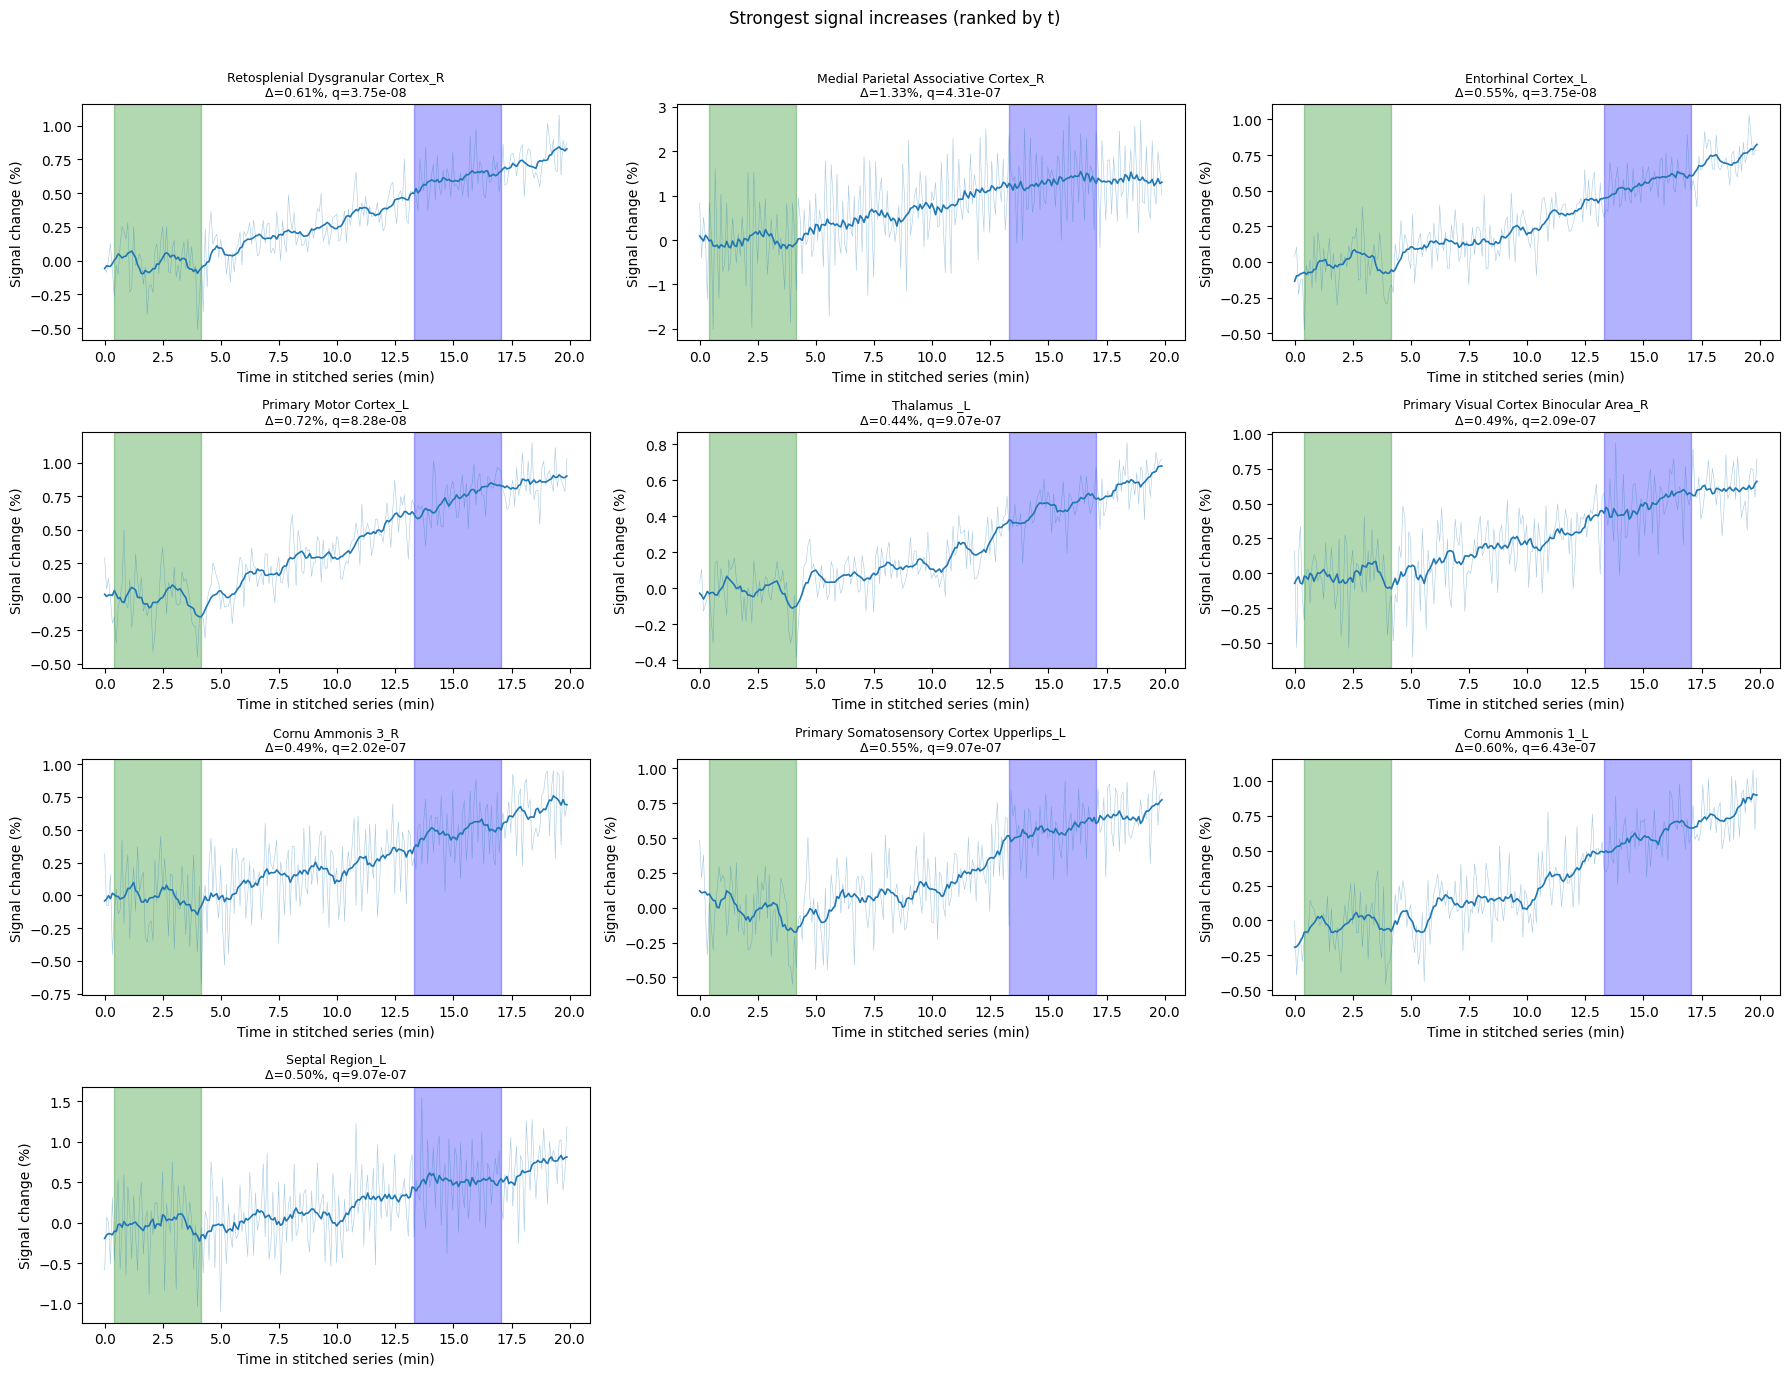

3 strongest signal decreases (ranked by t):
                                     name  n_voxels   baseline  signal_psc         t        p    q_fdr
                Amygdalopiriform Cortex_L         8 80505296.0   -0.805035 -3.913532 0.002113 0.003093
Lateral Entorhinal Cortex Internal part_L        11 73572416.0   -0.885430 -3.870131 0.005200 0.006976
                                   Pons_L        12 82419144.0   -0.137599 -1.460717 0.177090 0.187576


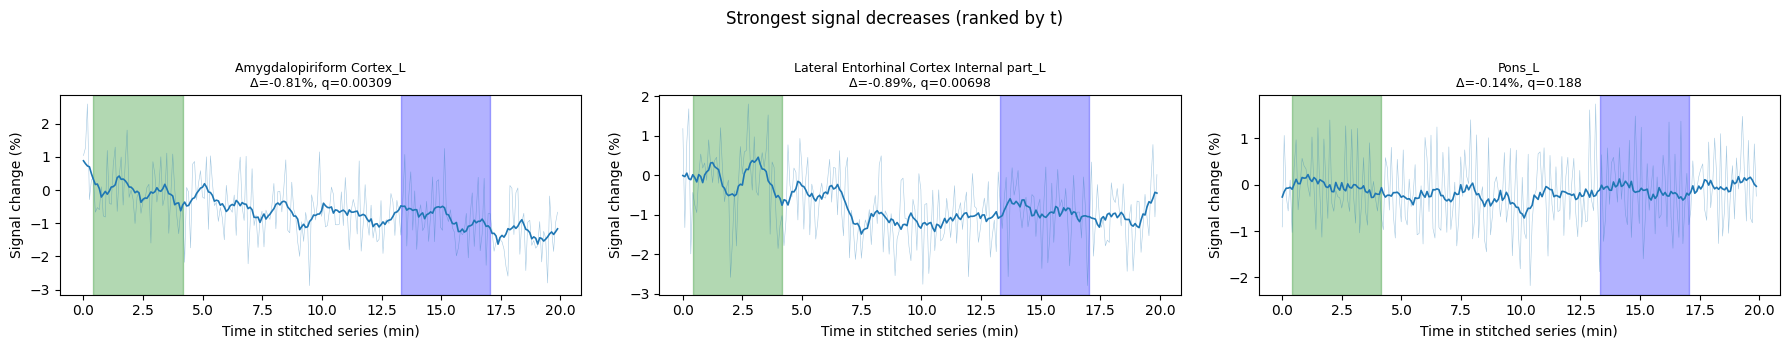

Figures saved in /Volumes/pschmidt/fmri_analysis/AnalysedData/Sordino_converted/RGRO_261026_0224_RN_SD_468/stitched_71_sordino_norm/analysis/roi_atlas_rat/poststim/plots (135 responders in /Volumes/pschmidt/fmri_analysis/AnalysedData/Sordino_converted/RGRO_261026_0224_RN_SD_468/stitched_71_sordino_norm/analysis/roi_atlas_rat/poststim/plots/responders)


In [9]:
from scipy import stats
from scipy.ndimage import uniform_filter1d
from statsmodels.stats.multitest import multipletests

MIN_VOXELS = 5
FDR_ALPHA = 0.05
N_TOP = 10  # regions shown per direction: the N_TOP strongest signal increases and the N_TOP strongest decreases
RANK_BY = "t"  # "t": by t-statistic (significance); "signal_psc": by size of the signal change in % (favours small, noisy regions)
PLOT_SMOOTH_S = 60  # smoothing of the plotted time courses
SAVE_ALL_REGION_PLOTS = True  # one figure per region in plots/ (responders always saved)

labels_img = nib.load(str(labels_funcspace))
labels = np.rint(labels_img.get_fdata()).astype(int)
if brain.shape != labels.shape:
    raise ValueError(f"Brain mask {brain.shape} and atlas labels {labels.shape} are on different grids.")
labels[~brain] = 0
label_names = load_label_names(atlas_names_entered.value.strip()) if atlas_names_entered.value.strip() else {}


def save_map(data, path):
    """Saves a map on the functional grid as float32 (the label image header would otherwise cast it to integers)."""
    header = labels_img.header.copy()
    header.set_data_dtype(np.float32)
    nib.save(nib.Nifti1Image(data.astype(np.float32), labels_img.affine, header), str(path))


smooth_vols = max(1, int(round(PLOT_SMOOTH_S / tr)))
t_min = np.arange(n_total) * tr / 60
plot_dir = post_dir / "plots"
(plot_dir / "responders").mkdir(parents=True, exist_ok=True)

rows, region_psc, region_bins = [], {}, {}
for lid in np.unique(labels[labels > 0]):
    sel = labels == lid
    n_vox = int(sel.sum())
    if n_vox < MIN_VOXELS:
        continue
    ts = func_4d[sel].mean(axis=0)
    b_bins, s_bins = window_bins(ts, base_start), window_bins(ts, sig_start)
    base = b_bins.mean()
    if base <= 0:
        continue
    t_stat, p_val = stats.ttest_ind(s_bins, b_bins, equal_var=False)
    name = label_names.get(int(lid), f"label_{lid}")
    region_psc[lid] = (ts - base) / base * 100
    region_bins[lid] = ((b_bins - base) / base * 100, (s_bins - base) / base * 100)
    rows.append({"label_id": int(lid), "name": name, "n_voxels": n_vox,
                 "baseline": base, "signal_psc": (s_bins.mean() - base) / base * 100, "t": t_stat, "p": p_val})

results = pd.DataFrame(rows)
valid = results["p"].notna()
results.loc[valid, "q_fdr"] = multipletests(results.loc[valid, "p"], alpha=FDR_ALPHA, method="fdr_bh")[1]
results = results.sort_values("p").reset_index(drop=True)
results["responder"] = (results["q_fdr"] < FDR_ALPHA) & (results["signal_psc"] > 0)

results.to_csv(post_dir / "poststim_roi_response.csv", index=False)
results[results["responder"]].to_csv(post_dir / "poststim_roi_responders.csv", index=False)
pd.DataFrame({results.loc[results.label_id == lid, "name"].iloc[0]: psc for lid, psc in region_psc.items()}).to_csv(
    post_dir / "poststim_roi_psc_timeseries_all.csv", index_label="volume")

print_statement(f"{len(results)} regions analysed, {int(results['responder'].sum())} with a significant signal increase (FDR q < {FDR_ALPHA})", bcolors.OKGREEN)
print(results.head(20).to_string(index=False))

# Map of the signal change in regions that respond
response_map = np.zeros(labels.shape, dtype=np.float32)
for r in results[results["responder"]].itertuples():
    response_map[labels == r.label_id] = r.signal_psc
save_map(response_map, post_dir / "poststim_roi_response_map.nii.gz")


def plot_time_course(ax, r, title_size=9):
    psc = region_psc[r.label_id]
    ax.plot(t_min, psc, lw=0.4, alpha=0.4)
    ax.plot(t_min, uniform_filter1d(psc, smooth_vols), lw=1.2, color="C0")
    mark_windows(ax)
    ax.set_xlabel("Time in stitched series (min)")
    ax.set_ylabel("Signal change (%)")
    ax.set_title(f"{r.name}\nΔ={r.signal_psc:.2f}%, q={r.q_fdr:.3g}", fontsize=title_size)


# Strongest regions: the N_TOP strongest signal increases and the N_TOP strongest decreases
def top_regions(sign):
    """The N_TOP regions with the strongest signal increase (sign=1) or decrease (sign=-1), ranked by RANK_BY."""
    column = "t" if RANK_BY == "t" else "signal_psc"
    candidates = results[(results["signal_psc"] * sign > 0) & results[column].notna()]
    return candidates.loc[(candidates[column] * sign).sort_values(ascending=False).index[:N_TOP]]


def plot_top_regions(top, title, out_file):
    n_rows = max(1, int(np.ceil(len(top) / 3)))
    fig, axes = plt.subplots(n_rows, 3, figsize=(18, 3.5 * n_rows), squeeze=False)
    for ax, r in zip(axes.flat, top.itertuples()):
        plot_time_course(ax, r)
    for ax in list(axes.flat)[len(top):]:
        ax.axis("off")
    fig.suptitle(title)
    fig.tight_layout(rect=(0, 0, 1, 0.97))
    fig.savefig(out_file, dpi=300)
    plt.show()


top_columns = ["name", "n_voxels", "baseline", "signal_psc", "t", "p", "q_fdr"]
for sign, label in ((1, "increase"), (-1, "decrease")):
    top = top_regions(sign)
    print_statement(f"{len(top)} strongest signal {label}s (ranked by {RANK_BY}):", bcolors.NOTIFICATION)
    print(top[top_columns].to_string(index=False))
    plot_top_regions(top, f"Strongest signal {label}s (ranked by {RANK_BY})", post_dir / f"poststim_roi_response_top_{label}s.svg")


def save_region_plot(r):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={"width_ratios": [3, 1]})
    plot_time_course(ax1, r, title_size=11)
    ax1.set_title(f"{r.name} ({r.n_voxels} voxels)")
    b, s = region_bins[r.label_id]
    ax2.boxplot([b, s], showfliers=False)
    for i, vals in enumerate((b, s), start=1):
        ax2.scatter(np.full(len(vals), i) + np.random.default_rng(0).uniform(-0.1, 0.1, len(vals)), vals, s=10, color="k", zorder=3)
    ax2.set_xticks([1, 2], ["Baseline", "Signal"])
    ax2.set_ylabel(f"Signal change (%), {BIN_S} s bins")
    ax2.set_title(f"t={r.t:.2f}, p={r.p:.3g}, q={r.q_fdr:.3g}")
    fig.tight_layout()
    fname = f"poststim_{r.label_id}_{safe_name(r.name)}.svg"
    if SAVE_ALL_REGION_PLOTS:
        fig.savefig(plot_dir / fname, dpi=300)
    if r.responder:
        fig.savefig(plot_dir / "responders" / fname, dpi=300)
    plt.close(fig)


for r in results.itertuples():
    if SAVE_ALL_REGION_PLOTS or r.responder:
        save_region_plot(r)
print_statement(f"Figures saved in {plot_dir} ({int(results['responder'].sum())} responders in {plot_dir / 'responders'})", bcolors.OKGREEN)

# Voxelwise Signal Change Maps in Atlas Space (for group analysis)

The region analysis above stays in native space, so the functional time series are never interpolated. For voxelwise group statistics, the maps are computed in native space and then moved to atlas space with the inverse of the functional → atlas matrix (struct2func and struct2atlas), in a single resampling step:
- `poststim_diff_psc`: mean signal-window minus baseline-window signal, in % of the baseline, per voxel (the signal change map of `mol_fMRI_v5.4.ipynb`).
- `poststim_tstat`: Welch t of the signal bins vs. the baseline bins per voxel.

The maps contain signal increases only (negative values are set to 0); set `POSITIVE_ONLY = False` in the code cell to keep decreases as well.
- `mean_func` and `brain_mask`, for overlays and for restricting the group statistics to the brain.

The bin images are smoothed with a Gaussian kernel (`SMOOTH_FWHM_MM`, within the brain mask) before the maps are computed. Set it to 0 to switch smoothing off.

Outputs go to `roi_atlas_<species>/poststim/native_maps/` and `.../atlas_space/` (on the registration template grid, which is the same for every animal of the species). Region-wise group comparisons can use `poststim_roi_response.csv` directly, since the atlas labels already define the same regions in every animal.

In [10]:
from scipy.ndimage import gaussian_filter

POSITIVE_ONLY = True  # only signal increases in the maps: negative values are set to 0 (False keeps both directions)
SMOOTH_FWHM_MM = 0.3  # as in mol_fMRI_v5.4 (rat); 0 = no smoothing, probably smaller for mouse

zooms = np.array(labels_img.header.get_zooms()[:3], dtype=float)
sigma_vox = SMOOTH_FWHM_MM / 2.3548 / zooms
brain_f = brain.astype(np.float32)
brain_weight = gaussian_filter(brain_f, sigma_vox) if SMOOTH_FWHM_MM > 0 else brain_f


def smooth_in_brain(img):
    """Gaussian smoothing that does not pull in signal from outside the brain mask."""
    if SMOOTH_FWHM_MM <= 0:
        return img * brain_f
    return np.where(brain_weight > 0, gaussian_filter(img * brain_f, sigma_vox) / np.where(brain_weight > 0, brain_weight, 1), 0)


def smoothed_bins(start):
    bins = window_bins(func_4d, start)
    return np.stack([smooth_in_brain(bins[..., k]) for k in range(bins.shape[-1])], axis=-1)


base_bins, sig_bins = smoothed_bins(base_start), smoothed_bins(sig_start)
base_img = base_bins.mean(axis=-1)
valid_vox = brain & (base_img > 0)
diff_map = np.where(valid_vox, (sig_bins.mean(axis=-1) - base_img) / np.where(valid_vox, base_img, 1) * 100, 0)
with np.errstate(divide="ignore", invalid="ignore"):
    t_map = stats.ttest_ind(sig_bins, base_bins, axis=-1, equal_var=False).statistic
t_map = np.where(valid_vox, np.nan_to_num(t_map), 0)
if POSITIVE_ONLY:
    diff_map = np.clip(diff_map, 0, None)
    t_map = np.clip(t_map, 0, None)

native_maps = post_dir / "native_maps"
native_maps.mkdir(exist_ok=True)
for name, data in (("poststim_diff_psc", diff_map), ("poststim_tstat", t_map)):
    save_map(data, native_maps / f"{name}.nii.gz")

# Native -> atlas: inverse of the functional -> atlas matrix, resampled once onto the registration template grid
atlas_space = post_dir / "atlas_space"
atlas_space.mkdir(exist_ok=True)
atlas_grid = prepare_registration_template(atlas_template, atlas_mask_text, species_cfg["reg_voxel_mm"], atlas_dir)
native_to_atlas = atlas_dir / "native_to_atlas.aff12.1D"
res = run_afni(["cat_matvec", "-ONELINE", composite, "-I"], capture=True)
native_to_atlas.write_text(res.stdout.strip() + "\n")

for name, source, interp in (("poststim_diff_psc", native_maps / "poststim_diff_psc.nii.gz", "linear"),
                             ("poststim_tstat", native_maps / "poststim_tstat.nii.gz", "linear"),
                             ("mean_func", func_reference, "linear"),
                             ("brain_mask", mask_file, "NN")):
    run_afni(["3dAllineate", "-source", source, "-base", atlas_grid, "-master", atlas_grid, "-1Dmatrix_apply", native_to_atlas,
              "-final", interp, "-prefix", atlas_space / f"{name}_atlasspace.nii.gz", "-overwrite"])
print_statement(f"[OK] Maps in atlas space: {atlas_space}", bcolors.OKGREEN)

# Check the alignment of the warped maps on the template
if OPEN_FSLEYES:
    subprocess.run(["fsleyes", str(atlas_grid), str(atlas_space / "poststim_tstat_atlasspace.nii.gz"), "-cm", "hot", "-dr", "2", "6"])

[COMMAND] cat_matvec -ONELINE /Volumes/pschmidt/fmri_analysis/AnalysedData/Sordino_converted/RGRO_261026_0224_RN_SD_468/stitched_71_sordino_norm/analysis/roi_atlas_rat/func_to_atlas_for_roi_apply.aff12.1D -I
[COMMAND] 3dAllineate -source /Volumes/pschmidt/fmri_analysis/AnalysedData/Sordino_converted/RGRO_261026_0224_RN_SD_468/stitched_71_sordino_norm/analysis/roi_atlas_rat/poststim/native_maps/poststim_diff_psc.nii.gz -base /Volumes/pschmidt/fmri_analysis/atlas/SIGMA_rat_atlas/sigma_wistar_rat_brain_templatesandatlases_version1-2-1_2022-08-26/SIGMA_Wistar_Rat_Brain_TemplatesAndAtlases_Version1.2.1/SIGMA_Rat_Anatomical_Imaging/SIGMA_Rat_Anatomical_InVivo_Template/SIGMA_InVivo_Brain_Template_Masked.nii -master /Volumes/pschmidt/fmri_analysis/atlas/SIGMA_rat_atlas/sigma_wistar_rat_brain_templatesandatlases_version1-2-1_2022-08-26/SIGMA_Wistar_Rat_Brain_TemplatesAndAtlases_Version1.2.1/SIGMA_Rat_Anatomical_Imaging/SIGMA_Rat_Anatomical_InVivo_Template/SIGMA_InVivo_Brain_Template_Masked.nii 

++ 3dAllineate: AFNI version=AFNI_26.2.06 (Sep  3 2026) [64-bit]
++ Authored by: Zhark the Registrator

** WARNING: NIfTI file /Volumes/pschmidt/fmri_analysis/AnalysedData/Sordino_converted/RGRO_261026_0224_RN_SD_468/stitched_71_sordino_norm/analysis/roi_atlas_rat/poststim/native_maps/poststim_diff_psc.nii.gz dimensions altered since AFNI extension was added
++ Source dataset: /Volumes/pschmidt/fmri_analysis/AnalysedData/Sordino_converted/RGRO_261026_0224_RN_SD_468/stitched_71_sordino_norm/analysis/roi_atlas_rat/poststim/native_maps/poststim_diff_psc.nii.gz
++ Base dataset:   /Volumes/pschmidt/fmri_analysis/atlas/SIGMA_rat_atlas/sigma_wistar_rat_brain_templatesandatlases_version1-2-1_2022-08-26/SIGMA_Wistar_Rat_Brain_TemplatesAndAtlases_Version1.2.1/SIGMA_Rat_Anatomical_Imaging/SIGMA_Rat_Anatomical_InVivo_Template/SIGMA_InVivo_Brain_Template_Masked.nii
++ Loading datasets into memory
 +        -cmass x y z shifts =   -0.379   -4.370   -1.781
 +  shift search range is +/- =    6.115   1

[COMMAND] 3dAllineate -source /Volumes/pschmidt/fmri_analysis/AnalysedData/Sordino_converted/RGRO_261026_0224_RN_SD_468/stitched_71_sordino_norm/analysis/roi_atlas_rat/poststim/native_maps/poststim_tstat.nii.gz -base /Volumes/pschmidt/fmri_analysis/atlas/SIGMA_rat_atlas/sigma_wistar_rat_brain_templatesandatlases_version1-2-1_2022-08-26/SIGMA_Wistar_Rat_Brain_TemplatesAndAtlases_Version1.2.1/SIGMA_Rat_Anatomical_Imaging/SIGMA_Rat_Anatomical_InVivo_Template/SIGMA_InVivo_Brain_Template_Masked.nii -master /Volumes/pschmidt/fmri_analysis/atlas/SIGMA_rat_atlas/sigma_wistar_rat_brain_templatesandatlases_version1-2-1_2022-08-26/SIGMA_Wistar_Rat_Brain_TemplatesAndAtlases_Version1.2.1/SIGMA_Rat_Anatomical_Imaging/SIGMA_Rat_Anatomical_InVivo_Template/SIGMA_InVivo_Brain_Template_Masked.nii -1Dmatrix_apply /Volumes/pschmidt/fmri_analysis/AnalysedData/Sordino_converted/RGRO_261026_0224_RN_SD_468/stitched_71_sordino_norm/analysis/roi_atlas_rat/native_to_atlas.aff12.1D -final linear -prefix /Volumes/p

++ Output dataset /Volumes/pschmidt/fmri_analysis/AnalysedData/Sordino_converted/RGRO_261026_0224_RN_SD_468/stitched_71_sordino_norm/analysis/roi_atlas_rat/poststim/atlas_space/poststim_tstat_atlasspace.nii.gz
++ 3dAllineate: total CPU time = 0.2 sec  Elapsed = 0.2
++ ###########################################################
++ 3dAllineate: AFNI version=AFNI_26.2.06 (Sep  3 2026) [64-bit]
++ Authored by: Zhark the Registrator
++ Source dataset: /Volumes/pschmidt/fmri_analysis/AnalysedData/Sordino_converted/RGRO_261026_0224_RN_SD_468/stitched_71_sordino_norm/analysis/mean_mc_func.nii.gz
++ Base dataset:   /Volumes/pschmidt/fmri_analysis/atlas/SIGMA_rat_atlas/sigma_wistar_rat_brain_templatesandatlases_version1-2-1_2022-08-26/SIGMA_Wistar_Rat_Brain_TemplatesAndAtlases_Version1.2.1/SIGMA_Rat_Anatomical_Imaging/SIGMA_Rat_Anatomical_InVivo_Template/SIGMA_InVivo_Brain_Template_Masked.nii
++ Loading datasets into memory
 +        -cmass x y z shifts =   -0.798   -4.769   -3.865
 +  shift sea

[COMMAND] 3dAllineate -source /Volumes/pschmidt/fmri_analysis/AnalysedData/Sordino_converted/RGRO_261026_0224_RN_SD_468/stitched_71_sordino_norm/analysis/mean_mc_func.nii.gz -base /Volumes/pschmidt/fmri_analysis/atlas/SIGMA_rat_atlas/sigma_wistar_rat_brain_templatesandatlases_version1-2-1_2022-08-26/SIGMA_Wistar_Rat_Brain_TemplatesAndAtlases_Version1.2.1/SIGMA_Rat_Anatomical_Imaging/SIGMA_Rat_Anatomical_InVivo_Template/SIGMA_InVivo_Brain_Template_Masked.nii -master /Volumes/pschmidt/fmri_analysis/atlas/SIGMA_rat_atlas/sigma_wistar_rat_brain_templatesandatlases_version1-2-1_2022-08-26/SIGMA_Wistar_Rat_Brain_TemplatesAndAtlases_Version1.2.1/SIGMA_Rat_Anatomical_Imaging/SIGMA_Rat_Anatomical_InVivo_Template/SIGMA_InVivo_Brain_Template_Masked.nii -1Dmatrix_apply /Volumes/pschmidt/fmri_analysis/AnalysedData/Sordino_converted/RGRO_261026_0224_RN_SD_468/stitched_71_sordino_norm/analysis/roi_atlas_rat/native_to_atlas.aff12.1D -final linear -prefix /Volumes/pschmidt/fmri_analysis/AnalysedData/So

++ Output dataset /Volumes/pschmidt/fmri_analysis/AnalysedData/Sordino_converted/RGRO_261026_0224_RN_SD_468/stitched_71_sordino_norm/analysis/roi_atlas_rat/poststim/atlas_space/mean_func_atlasspace.nii.gz
++ 3dAllineate: total CPU time = 0.6 sec  Elapsed = 0.7
++ ###########################################################
++ 3dAllineate: AFNI version=AFNI_26.2.06 (Sep  3 2026) [64-bit]
++ Authored by: Zhark the Registrator
++ Source dataset: /Volumes/pschmidt/fmri_analysis/AnalysedData/Sordino_converted/RGRO_261026_0224_RN_SD_468/stitched_71_sordino_norm/mask_mean_mc_func.nii.gz
++ Base dataset:   /Volumes/pschmidt/fmri_analysis/atlas/SIGMA_rat_atlas/sigma_wistar_rat_brain_templatesandatlases_version1-2-1_2022-08-26/SIGMA_Wistar_Rat_Brain_TemplatesAndAtlases_Version1.2.1/SIGMA_Rat_Anatomical_Imaging/SIGMA_Rat_Anatomical_InVivo_Template/SIGMA_InVivo_Brain_Template_Masked.nii
++ Loading datasets into memory
 +        -cmass x y z shifts =   -0.680   -4.311   -1.918
 +  shift search range

[COMMAND] 3dAllineate -source /Volumes/pschmidt/fmri_analysis/AnalysedData/Sordino_converted/RGRO_261026_0224_RN_SD_468/stitched_71_sordino_norm/mask_mean_mc_func.nii.gz -base /Volumes/pschmidt/fmri_analysis/atlas/SIGMA_rat_atlas/sigma_wistar_rat_brain_templatesandatlases_version1-2-1_2022-08-26/SIGMA_Wistar_Rat_Brain_TemplatesAndAtlases_Version1.2.1/SIGMA_Rat_Anatomical_Imaging/SIGMA_Rat_Anatomical_InVivo_Template/SIGMA_InVivo_Brain_Template_Masked.nii -master /Volumes/pschmidt/fmri_analysis/atlas/SIGMA_rat_atlas/sigma_wistar_rat_brain_templatesandatlases_version1-2-1_2022-08-26/SIGMA_Wistar_Rat_Brain_TemplatesAndAtlases_Version1.2.1/SIGMA_Rat_Anatomical_Imaging/SIGMA_Rat_Anatomical_InVivo_Template/SIGMA_InVivo_Brain_Template_Masked.nii -1Dmatrix_apply /Volumes/pschmidt/fmri_analysis/AnalysedData/Sordino_converted/RGRO_261026_0224_RN_SD_468/stitched_71_sordino_norm/analysis/roi_atlas_rat/native_to_atlas.aff12.1D -final NN -prefix /Volumes/pschmidt/fmri_analysis/AnalysedData/Sordino_co